In [70]:
%env TALLTABLE_DB_DIR=/mnt/sdceph/users/spherex/talltable

import duckdb
import healpy
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

from astropy import constants as const
from astropy import units as u
from astropy.coordinates import SkyCoord
from astropy.cosmology import Planck18
from astropy.io import fits
from astropy.visualization import make_lupton_rgb, ManualInterval
from astroquery.ipac.irsa import Irsa
from pprint import pprint
from tqdm.auto import tqdm

from talltable import PixelQuery

env: TALLTABLE_DB_DIR=/mnt/sdceph/users/spherex/talltable


In [4]:
with fits.open('../data/LRG_NGC_clustering.dat.fits') as hdul:
    data = hdul[1].data

## masking

### wavelength selection

pick one narrow-ish wavelength band per detector

In [5]:
BITMASK_COL = 2**11 - 2**0
BITMASK_ROW = 2**23 - 2**12
BITMASK_DET = 2**27 - 2**24

rng = np.random.default_rng(119)

result = duckdb.sql(f"""
SELECT
    -- waveid,
    min(wavelength) AS min_lam, max(wavelength) AS max_lam,
    -- bandwidth,
    -- (waveid & {BITMASK_ROW}) >> 12 AS row,
    -- (waveid & {BITMASK_COL})       AS col,
    (waveid & {BITMASK_DET}) >> 24 AS det
FROM read_parquet('/mnt/sdceph/users/spherex/talltable/waves.parquet')
GROUP BY det
ORDER BY det
""").fetchnumpy()

wave_bands = {}
for i in range(len(result['det'])):
    _det = result['det'][i]
    _min = result['min_lam'][i]
    _max = result['max_lam'][i]
    
    r = rng.uniform(low=0.3, high=0.7)
    lam_c = (1 - r) * _min + r * _max
    wave_bands[_det] = (lam_c - 0.1, lam_c + 0.1)

    assert lam_c - 0.1 > _min
    assert lam_c + 0.1 < _max

    print(f'det {_det}: actual band ({_min:.3f}, {_max:.3f}), chosen band ({lam_c - 0.1:.3f}, {lam_c + 0.1:.3f})')

det 1: actual band (0.735, 1.127), chosen band (0.902, 1.102)
det 2: actual band (1.085, 1.668), chosen band (1.331, 1.531)
det 3: actual band (1.616, 2.440), chosen band (2.033, 2.233)
det 4: actual band (2.395, 3.867), chosen band (2.821, 3.021)
det 5: actual band (3.792, 4.439), chosen band (4.082, 4.282)
det 6: actual band (4.395, 5.019), chosen band (4.488, 4.688)


In [128]:
import healpy as hp
from talltable.query import indices_to_hphigh_ranges, choose_filter_level

def query_ranges_sql(ra, dec, radius_deg, level=13):
    ipix_L = hp.query_disc(
        2**level, hp.ang2vec(ra, dec, lonlat=True),
        np.radians(radius_deg), nest=True, inclusive=True,
    )
    ranges = indices_to_hphigh_ranges(ipix_L, level)

    return '(' + '\nOR '.join(
        f'(p.hphigh BETWEEN {lo} AND {hi})'
        for (lo, hi) in ranges
    ) + ')'

In [129]:
from talltable.pixel_query import _disc_rect_hphigh_ranges
from talltable.partition import find_partitions_disc

def pixels_table_sql(ra, dec, radius_deg):
    part_nums = find_partitions_disc(ra, dec, radius_deg)
    paths_sql = ','.join([
        f"'/mnt/sdceph/users/spherex/talltable/pixels/part={p}/compacted.parquet'"
        for p in part_nums
    ])
    if len(part_nums) > 1:
        paths_sql = f'[{paths_sql}]'
    return f"read_parquet({paths_sql})"

# def query_ranges_sql(ra, dec, radius_deg):
#     ranges = _disc_rect_hphigh_ranges(("disc", ra, dec, radius_deg))
#     return '(' + '\nOR '.join(
#         f'(p.hphigh BETWEEN {lo} AND {hi})'
#         for (lo, hi) in ranges
#     ) + ')'


def query_gaia(ra, dec, radius_deg, mag_limit=20.0):
    coord = SkyCoord(ra=ra, dec=dec, frame="icrs", unit="deg")
 
    table = Irsa.query_region(
        coord,
        catalog="gaia_dr3_source",
        spatial="Cone",
        radius=radius_deg * u.deg,
        columns="source_id,ra,dec,phot_g_mean_mag,phot_bp_mean_mag,phot_rp_mean_mag",
    )

    # hard cut on G magnitude
    table = table[table["phot_g_mean_mag"] < mag_limit]
    return table

### crude mask radius

pick a crude mask radius that is at least as large as the spherex solution (eq 14 + table 19, explanatory supplement)

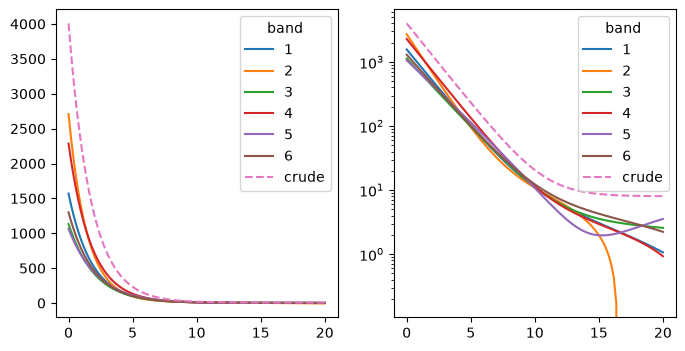

In [130]:
def spherex_mask_radius(m, band):
    a, b, c, d, e = {
        1: (1549.4, -0.568, 21.7, -0.114, -1.17),
        2: (2687.3, -0.700, 452.1, -0.003, -430.3),
        3: (1129.4, -0.496, 396.4, -0.0002, -392.3),
        4: (2277.9, -0.575, 1102.5, -0.0003, -1095.0),
        5: (1072.98, -0.44, 11491.65, 5e-5, -11499.76),
        6: (1291.4, -0.522, 1579.8, -0.0002, -1571.3),
    }[band]

    return a * np.exp(b * m) + c * np.exp(d * m) + e

def crude_mask_radius(m):
    return 8.0 + 4e3 * 10 ** (-0.25 * m)


m = np.linspace(0, 20, 100)

plt.figure(figsize=(8, 4))
plt.subplot(121)
for band in range(1, 7):
    plt.plot(m, spherex_mask_radius(m, band), label=band)
plt.plot(m, crude_mask_radius(m), label='crude', ls='--')
plt.legend(title='band')

plt.subplot(122)
for band in range(1, 7):
    plt.plot(m, spherex_mask_radius(m, band), label=band)
plt.plot(m, crude_mask_radius(m), label='crude', ls='--')
plt.legend(title='band')
plt.yscale('log')
plt.show()

In [131]:
def _mdpt(x1, x2):
    return 0.5 * (x1 + x2)

band_centers = {d: _mdpt(*wave_bands[d]) for d in wave_bands}

### visualize Gaia masking

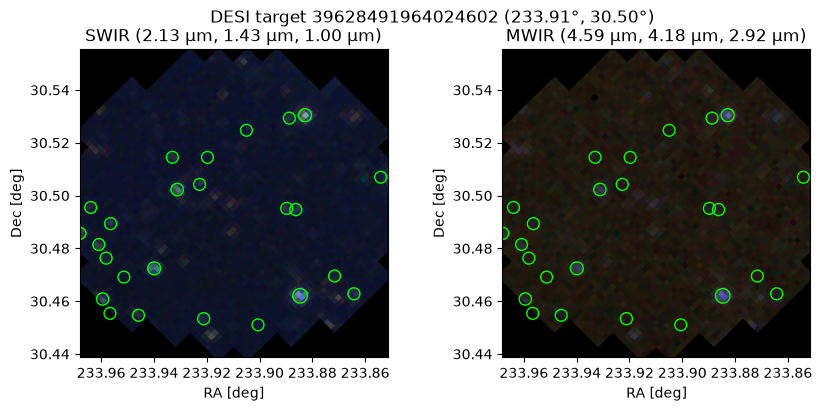

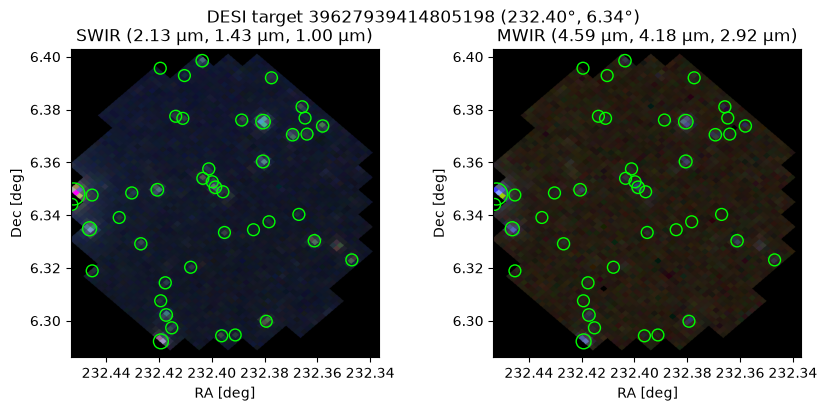

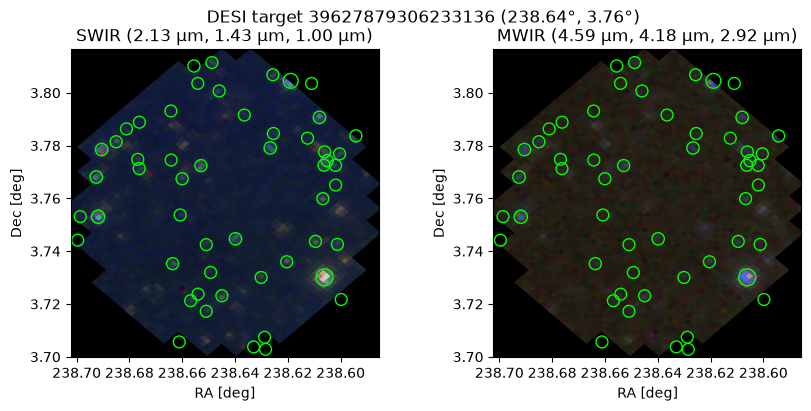

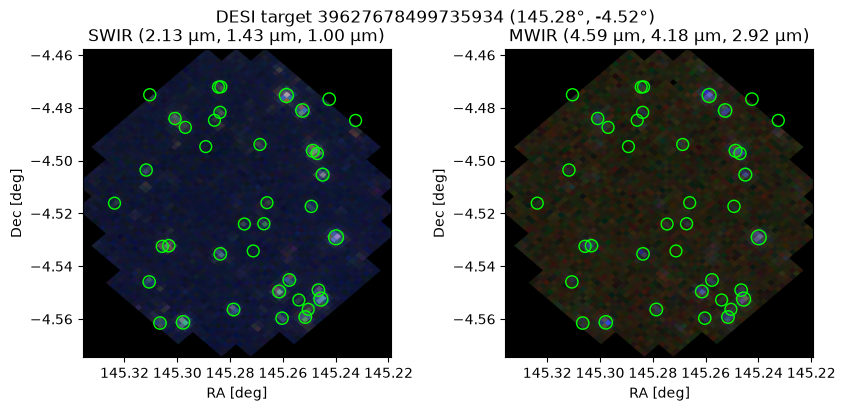

In [132]:
rng = np.random.default_rng(130)

angwid = 3.5 / 60
nvis = int(np.ceil(2 * angwid * 10 / (healpy.nside2resol(2**15, arcmin=True) / 60)))

choices = rng.choice(len(data), size=(4,))

for choice in choices:
    ra = data['RA'][choice]
    dec = data['DEC'][choice]
    z = data['Z'][choice]
    tgt = data['TARGETID'][choice]

    hpmap = np.zeros((6, 12 * 4**15), dtype=np.float32)

    for i, (lo, hi) in enumerate(wave_bands.values()):
        query = f"""
WITH waves AS (
    SELECT * FROM read_parquet('/mnt/sdceph/users/spherex/talltable/waves.parquet')
    WHERE wavelength BETWEEN {lo} AND {hi}
)
SELECT
    p.hphigh >> (2 * (22 - 15)) AS map_idx,
    weighted_avg(p.flux - p.zodi, 1.0 / p.variance) AS map_val
FROM {pixels_table_sql(ra, dec, 3 / 60)} p
JOIN waves w ON p.waveid = w.waveid
WHERE {query_ranges_sql(ra, dec, 3 / 60)}
    AND (p.flags & ~(1 << 21) = 0)
GROUP BY ALL"""
    
        result = duckdb.sql(query).fetchnumpy()
        np.add.at(hpmap[i], result['map_idx'], result['map_val'])

    gaia_sources = query_gaia(ra, dec, 3.5 / 60)
    
    plot_ra  = np.linspace(ra - angwid,  ra + angwid,  nvis)
    plot_dec = np.linspace(dec - angwid, dec + angwid, nvis)
    plot_ra, plot_dec = np.meshgrid(plot_ra, plot_dec, indexing='xy')
    indices = healpy.ang2pix(2**15, plot_ra, plot_dec, nest=True, lonlat=True)

    lup_kw = dict(interval=ManualInterval(vmin=0), Q=10, stretch=0.5)
    ims_kw = dict(origin='lower', extent=(ra - angwid, ra + angwid, dec - angwid, dec + angwid))

    fig, axs = plt.subplots(1, 2, figsize=(10, 4))

    axs[0].imshow(make_lupton_rgb(hpmap[2, indices], hpmap[1, indices], hpmap[0, indices], **lup_kw), **ims_kw)
    axs[1].imshow(make_lupton_rgb(hpmap[5, indices], hpmap[4, indices], hpmap[3, indices], **lup_kw), **ims_kw)

    for ax in axs.flat:
        ax.xaxis.set_inverted(True)
        ax.set_xlabel('RA [deg]')
        ax.set_ylabel('Dec [deg]')

        for src in gaia_sources:
            ax.add_patch(mpl.patches.Circle(
                (src['ra'], src['dec']),
                radius=crude_mask_radius(src['phot_g_mean_mag']) / 3600,
                facecolor='none', edgecolor='#00FF00',
                transform=ax.transData
            ))
    
    axs[0].set_title(f'SWIR ({band_centers[3]:.2f} µm, {band_centers[2]:.2f} µm, {band_centers[1]:.2f} µm)')
    axs[1].set_title(f'MWIR ({band_centers[6]:.2f} µm, {band_centers[5]:.2f} µm, {band_centers[4]:.2f} µm)')

    fig.suptitle(f'DESI target {tgt} ({ra:.2f}°, {dec:.2f}°)')
    
    plt.show()

### query with masks excluded

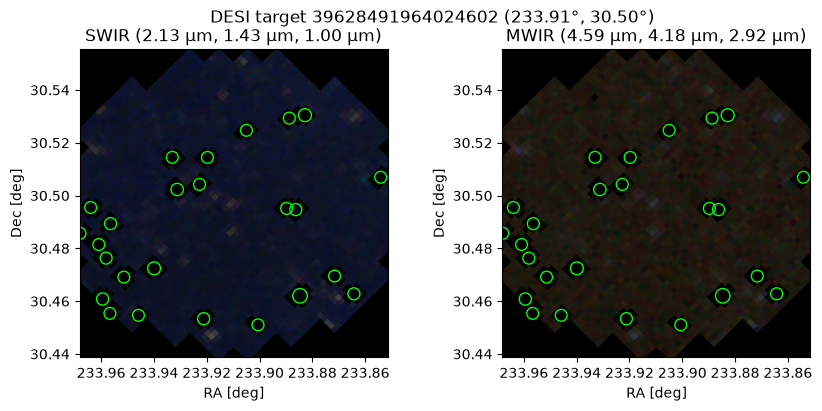

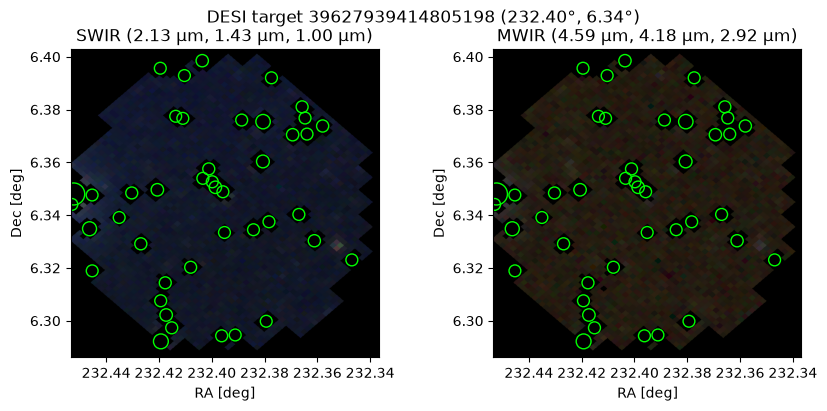

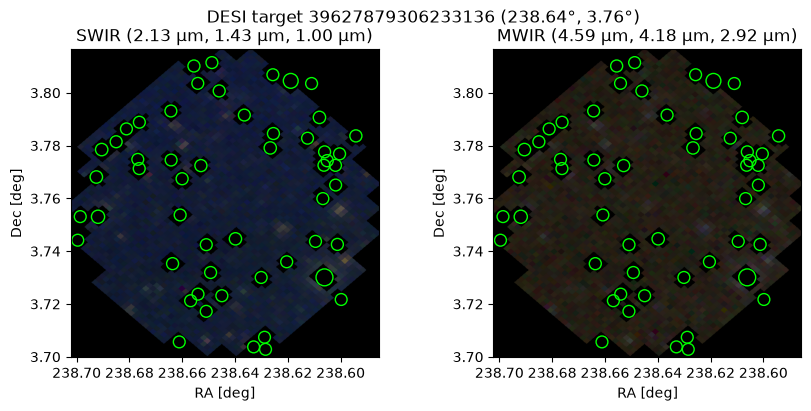

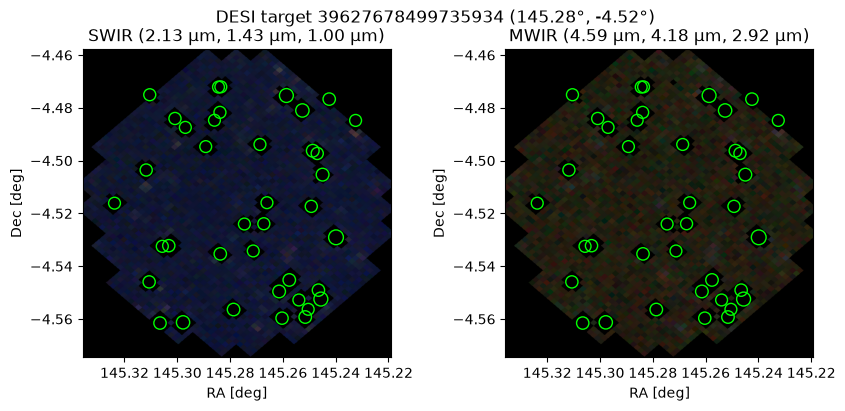

In [136]:
rng = np.random.default_rng(130)

angwid = 3.5 / 60
nvis = int(np.ceil(2 * angwid * 10 / (healpy.nside2resol(2**15, arcmin=True) / 60)))

choices = rng.choice(len(data), size=(4,))

for choice in choices:
    ra = data['RA'][choice]
    dec = data['DEC'][choice]
    z = data['Z'][choice]
    tgt = data['TARGETID'][choice]

    gaia_sources = query_gaia(ra, dec, 3.5 / 60)
    mask_ranges_sql = '\nAND '.join([
        'NOT ' + query_ranges_sql(
            src['ra'], src['dec'],
            crude_mask_radius(src['phot_g_mean_mag']) / 3600,
            level=15,
        ) for src in gaia_sources
    ])

    hpmap = np.zeros((6, 12 * 4**15), dtype=np.float32)

    for i, (lo, hi) in enumerate(wave_bands.values()):
        query = f"""
WITH waves AS (
    SELECT * FROM read_parquet('/mnt/sdceph/users/spherex/talltable/waves.parquet')
    WHERE wavelength BETWEEN {lo} AND {hi}
)
SELECT
    p.hphigh >> (2 * (22 - 15)) AS map_idx,
    weighted_avg(p.flux - p.zodi, 1.0 / p.variance) AS map_val
FROM {pixels_table_sql(ra, dec, 3 / 60)} p
JOIN waves w ON p.waveid = w.waveid
WHERE {query_ranges_sql(ra, dec, 3 / 60)} AND ({mask_ranges_sql})
    AND (p.flags & ~(1 << 21) = 0)
GROUP BY ALL"""
    
        result = duckdb.sql(query).fetchnumpy()
        np.add.at(hpmap[i], result['map_idx'], result['map_val'])

    plot_ra  = np.linspace(ra - angwid,  ra + angwid,  nvis)
    plot_dec = np.linspace(dec - angwid, dec + angwid, nvis)
    plot_ra, plot_dec = np.meshgrid(plot_ra, plot_dec, indexing='xy')
    indices = healpy.ang2pix(2**15, plot_ra, plot_dec, nest=True, lonlat=True)

    lup_kw = dict(interval=ManualInterval(vmin=0), Q=10, stretch=0.5)
    ims_kw = dict(origin='lower', extent=(ra - angwid, ra + angwid, dec - angwid, dec + angwid))

    fig, axs = plt.subplots(1, 2, figsize=(10, 4))

    axs[0].imshow(make_lupton_rgb(hpmap[2, indices], hpmap[1, indices], hpmap[0, indices], **lup_kw), **ims_kw)
    axs[1].imshow(make_lupton_rgb(hpmap[5, indices], hpmap[4, indices], hpmap[3, indices], **lup_kw), **ims_kw)

    for ax in axs.flat:
        ax.xaxis.set_inverted(True)
        ax.set_xlabel('RA [deg]')
        ax.set_ylabel('Dec [deg]')

        for src in gaia_sources:
            ax.add_patch(mpl.patches.Circle(
                (src['ra'], src['dec']),
                radius=crude_mask_radius(src['phot_g_mean_mag']) / 3600,
                facecolor='none', edgecolor='#00FF00',
                transform=ax.transData
            ))
    
    axs[0].set_title(f'SWIR ({band_centers[3]:.2f} µm, {band_centers[2]:.2f} µm, {band_centers[1]:.2f} µm)')
    axs[1].set_title(f'MWIR ({band_centers[6]:.2f} µm, {band_centers[5]:.2f} µm, {band_centers[4]:.2f} µm)')

    fig.suptitle(f'DESI target {tgt} ({ra:.2f}°, {dec:.2f}°)')
    
    plt.show()

## stacking

In [219]:
Z_MIN, Z_MAX = 0.5, 0.51
N_GALAXIES = 1_000          # sample size

WL_REST_HALPHA = 0.656    # µm
N_WL_BINS = 11
RESOLUTION = 120

QUERY_RADIUS_ARCMIN = 2.0

### sample selection

In [240]:
rng = np.random.default_rng(112)

mask = (data['Z'] > Z_MIN) & (data['Z'] < Z_MAX)
sample = data[mask]

# hp15 = healpy.ang2pix(2**15, sample['RA'], sample['DEC'], nest=True, lonlat=True)
# sort_idx = np.argsort(hp15)

# sample = sample[sort_idx]
# hp15 = hp15[sort_idx]

if not (N_GALAXIES is None or N_GALAXIES >= len(hp15)):
    # chosen = rng.choice(len(hp15), size=1).item()
    # lo = max(0, chosen - N_GALAXIES // 2)
    # hi = min(len(hp15), lo + N_GALAXIES)
    # lo = hi - N_GALAXIES

    # tiny_mask = np.zeros_like(hp15, dtype=bool)
    # tiny_mask[lo:hi] = True
    # sample = sample[tiny_mask]

    chosen = rng.choice(len(sample), size=(N_GALAXIES), replace=False)
    sample = sample[chosen]

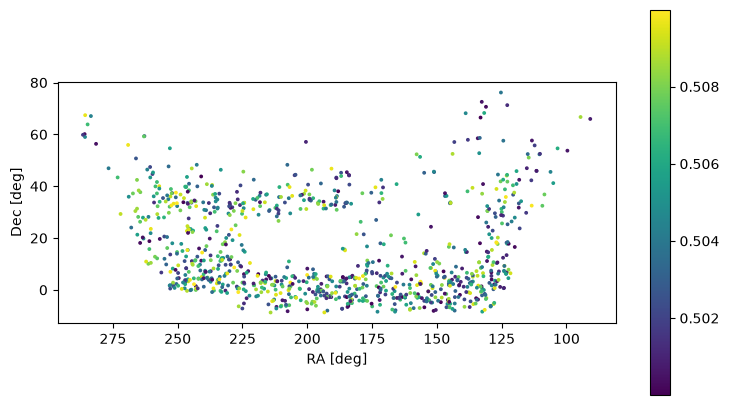

In [241]:
fig, ax = plt.subplots(figsize=(9, 5))
_s = ax.scatter(sample['RA'], sample['DEC'], c=sample['Z'], marker='o', s=3)
ax.axis('scaled')
ax.xaxis.set_inverted(True)
ax.set_xlabel('RA [deg]')
ax.set_ylabel('Dec [deg]')
fig.colorbar(_s)
plt.show()

### choose bin edges

In [242]:
z_min, z_max = sample['Z'].min(), sample['Z'].max()

r_max = (QUERY_RADIUS_ARCMIN * u.arcmin).to(u.rad).value \
        * Planck18.comoving_transverse_distance(z_max).to(u.Mpc).value
r_bins = np.linspace(0, r_max, 32)

# narrow rest-frame band around H-alpha, log-spaced at resolution R = lambda/dlambda
half_ln_width = (N_WL_BINS / RESOLUTION) / 2
WL_REST_MIN = WL_REST_HALPHA * np.exp(-half_ln_width)
WL_REST_MAX = WL_REST_HALPHA * np.exp(+half_ln_width)
wl_bins = np.geomspace(WL_REST_MIN, WL_REST_MAX, N_WL_BINS + 1)

# fixed observed-frame query band wide enough to cover every galaxy's redshifted H-alpha window
QUERY_WL_MIN = WL_REST_MIN * (1 + Z_MIN)
QUERY_WL_MAX = WL_REST_MAX * (1 + Z_MAX)

n_r, n_wl = len(r_bins) - 1, len(wl_bins) - 1

### query & stack

In [ ]:
import threading
import time
from concurrent.futures import ThreadPoolExecutor, as_completed
from pyvo.dal.exceptions import DALServiceError

def query_gaia_retry(ra, dec, radius_deg, max_retries=5):
    for attempt in range(max_retries):
        try:
            return query_gaia(ra, dec, radius_deg)
        except DALServiceError as e:
            if attempt == max_retries - 1:
                raise
            wait = 2 ** attempt + np.random.uniform(0, 1)
            time.sleep(wait)

_local = threading.local()

def get_con():
    if not hasattr(_local, "con"):
        _local.con = duckdb.connect()
    return _local.con

def process_row(row):
    ra, dec, z = row['RA'], row['DEC'], row['Z']

    gaia_sources = query_gaia_retry(ra, dec, (QUERY_RADIUS_ARCMIN + 0.5) / 60)
    mask_ranges_sql = '\nAND '.join([
        'NOT ' + query_ranges_sql(
            src['ra'], src['dec'],
            crude_mask_radius(src['phot_g_mean_mag']) / 3600,
            level=15,
        ) for src in gaia_sources
    ])

    query = f"""
WITH waves AS (
    SELECT * FROM read_parquet('/mnt/sdceph/users/spherex/talltable/waves.parquet')
    WHERE wavelength BETWEEN {QUERY_WL_MIN} AND {QUERY_WL_MAX}
)
SELECT p.imageid, p.flux, p.zodi, p.variance, p.hphigh, p.waveid
     , w.wavelength, w.bandwidth
FROM {pixels_table_sql(ra, dec, QUERY_RADIUS_ARCMIN / 60)} p
JOIN waves w ON p.waveid = w.waveid
WHERE {query_ranges_sql(ra, dec, QUERY_RADIUS_ARCMIN / 60)}
AND ({mask_ranges_sql})
AND (p.flags & ~(1 << 21) = 0)
"""
    _table = get_con().sql(query).to_arrow_table()

    gal_coord = SkyCoord(ra=ra, dec=dec, unit='deg')
    pra, pdec = healpy.pix2ang(2**22, _table.column("hphigh").to_numpy(), nest=True, lonlat=True)
    pixel_coords = SkyCoord(ra=pra, dec=pdec, unit='deg')

    dist = gal_coord.separation(pixel_coords).to(u.rad).value \
           * Planck18.comoving_transverse_distance(z)
    r_rest = dist.to(u.Mpc).value

    wavelen_obs   = _table.column("wavelength").to_numpy()
    freq_obs      = (const.c / (wavelen_obs * u.micrometer)).to(u.Hz).value
    intensity_obs = freq_obs * (_table.column("flux").to_numpy() - _table.column("zodi").to_numpy())

    wl_rest = wavelen_obs / (1 + z)
    I_rest  = (1 + z)**4 * intensity_obs

    i_r  = np.digitize(r_rest,  r_bins)  - 1
    i_wl = np.digitize(wl_rest, wl_bins) - 1
    valid = (i_r >= 0) & (i_r < n_r) & (i_wl >= 0) & (i_wl < n_wl)

    return i_r[valid], i_wl[valid], I_rest[valid]


sum_I  = np.zeros((n_r, n_wl))
sum_I2 = np.zeros((n_r, n_wl))
count  = np.zeros((n_r, n_wl), dtype=np.int64)

with ThreadPoolExecutor(max_workers=8) as ex:
    futures = [ex.submit(process_row, row) for row in sample]
    for fut in tqdm(as_completed(futures), total=len(sample)):
        i_r_v, i_wl_v, I_v = fut.result()
        np.add.at(sum_I,  (i_r_v, i_wl_v), I_v)
        np.add.at(sum_I2, (i_r_v, i_wl_v), I_v ** 2)
        np.add.at(count,  (i_r_v, i_wl_v), 1)

  0%|          | 0/1000 [00:00<?, ?it/s]

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

... (287 outputs left out)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



In [ ]:
# mean intensity per (r, wavelength) bin == WW/DD of the marked-correlation-function estimator,
# with "mark" = pixel intensity and pair count = `count`
stack = np.where(count > 0, sum_I / count, np.nan)
variance  = np.where(count > 1, sum_I2 / count - (sum_I / count) ** 2, np.nan)
stack_err = np.sqrt(variance / count)   # SEM = sample std / sqrt(N), not stack/sqrt(count)

r_c  = 0.5 * (r_bins[:-1] + r_bins[1:])
wl_c = 0.5 * (wl_bins[:-1] + wl_bins[1:])

### background subtraction

In [ ]:
outer = r_c > 0.8 * r_c.max()
background = np.nanmean(stack[outer, :], axis=0)
stack_bgsub = stack - background[None, :]

### visualize

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(9, 5))
cmap = plt.get_cmap('viridis')
norm = mpl.colors.Normalize(r_c.min(), r_c.max())
for i in range(n_r):
    axs[0].errorbar(wl_c * 1e3, stack[i], yerr=stack_err[i],
                     marker='o', color=cmap(norm(r_c[i])))
axs[0].set_xlabel('wavelength [nm]')
axs[0].set_ylabel(r'$\nu I_\nu$')
axs[0].set_title('Absolute')
fig.colorbar(mpl.cm.ScalarMappable(norm, cmap), ax=axs[0], label=r'$r$ [cMpc]', location='bottom')

for i in range(n_r):
    axs[1].errorbar(wl_c * 1e3, stack_bgsub[i], yerr=stack_err[i],
                     marker='o', color=cmap(norm(r_c[i])))
axs[1].set_xlabel('wavelength [nm]')
axs[1].set_title('Background-subtracted')
fig.colorbar(mpl.cm.ScalarMappable(norm, cmap), ax=axs[1], label=r'$r$ [cMpc]', location='bottom')

plt.show()

In [ ]:
cmap = plt.get_cmap('rainbow')
norm = mpl.colors.Normalize(wl_bins.min(), wl_bins.max())

fig, ax = plt.subplots()
for j in range(n_wl):
    ax.plot(r_c, count[:, j], color=cmap(norm(wl_c[j])), marker='o', label=f'{wl_c[j]:.2f} um')
ax.set_xlabel('r_comoving [Mpc]')
fig.colorbar(mpl.cm.ScalarMappable(norm, cmap), ax=ax, label='Wavelength [µm]')
ax.set_yscale('log')
ax.set_ylabel("Measurement count")
plt.show()

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(9, 4))
for j in range(0, n_wl, 2):
    axs[0].errorbar(r_c, stack[:, j], yerr=stack_err[:, j], marker='o', label=f'{wl_c[j] * 1000:.0f} nm')
axs[0].set_xlabel('$r$ [cMpc]')
axs[0].set_ylabel(r'$\nu I_\nu$')
axs[0].set_title("Absolute")
axs[0].legend(title='wavelength')

for j in range(0, n_wl, 2):
    axs[1].errorbar(r_c, stack_bgsub[:, j], yerr=stack_err[:, j], marker='o', label=f'{wl_c[j] * 1000:.0f} nm')
axs[1].set_xlabel('$r$ [cMpc]')
axs[1].set_title("Background-subtracted")
axs[1].legend(title='wavelength')
plt.show()